In [2]:
import numpy as np
import matplotlib.pyplot as plt

import sys
sys.path.append('..')
from functions.qite_gci import *
from functions.qite_dme import *

plt.rcParams['axes.labelsize'] = 16
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['font.size'] = 16
plt.rcParams['savefig.dpi'] = 75
plt.rcParams['lines.linewidth'] = 2.0
plt.rcParams['lines.markersize'] = 8
plt.rcParams['legend.fontsize'] = 14
plt.rcParams['legend.labelspacing'] = .3
plt.rcParams['legend.columnspacing']= .3
plt.rcParams['legend.handletextpad']= .1
plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = "serif"
plt.rcParams['font.serif'] = "cm"
plt.rcParams["figure.figsize"] = [5, 3.50]
plt.rcParams["figure.autolayout"] = True

[Qibo 0.2.12|ERROR|2025-04-26 18:47:24]: The 'qibojit' backends' provider is not available. Check that a Python package named 'qibojit' is installed, and it is exposing valid Qibo backends.
[Qibo 0.2.12|ERROR|2025-04-26 18:47:24]: The 'qibojit' backends' provider is not available. Check that a Python package named 'qibojit' is installed, and it is exposing valid Qibo backends.
[Qibo 0.2.12|INFO|2025-04-26 18:47:24]: Using numpy backend on /CPU:0


In [3]:
max_k = 6
max_M = 50
psi0 = np.sqrt(1/2)*np.array([[1],[1j]])
optimal_s_Mk = []
for M in range(1,max_M+1):
    optimal_s_for_constant_M = []
    for k in range(1,max_k+1):
        def dbqite(s):
            return GCI(QITE_dme_select_M(M), psi0, None, optimal_s_for_constant_M + [s]).execute_gci()[0][-1].real
        result = minimize(dbqite, 0.6, method='BFGS')
        optimal_s_for_constant_M = optimal_s_for_constant_M + [result.x[0]]
    optimal_s_Mk.append(optimal_s_for_constant_M)

optimal_s_Mk = np.asarray(optimal_s_Mk)
optimal_s_kM = optimal_s_Mk.T
np.save('optimal_s_Mk', optimal_s_Mk)

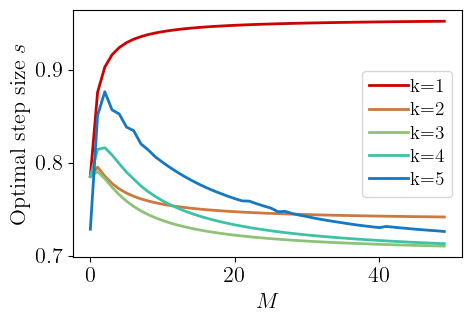

In [27]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import cm
n_colors = 6
dark_factor = 0.8
color = [(r * dark_factor, g * dark_factor, b * dark_factor, a) 
         for r, g, b, a in cm.rainbow(np.linspace(1, 0, n_colors))]
markers = ['o','s','^','*','P','*','h']

i=0
for s_list in optimal_s_kM[:-1]:
    s_list = [x if x > 0.6 else None for x in s_list]
    plt.plot(s_list,color=color[i],label=f'k={i+1}')
    i+=1

plt.ylabel(r'Optimal step size $s$')
plt.xlabel(r'$M$')
plt.legend()
plt.savefig('plots/optimal_s.pdf')

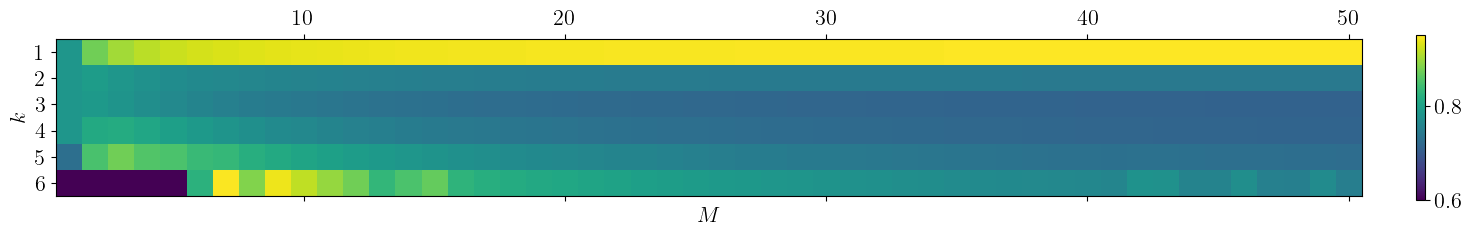

In [23]:
import matplotlib.pyplot as plt
import numpy as np

# Create the plot with a specific figure size
fig, ax = plt.subplots(figsize=(15, 10))
cax = ax.matshow(optimal_s_kM)

# Adjust axis ticks
ax.set_xticks(np.arange(9, optimal_s_kM.shape[1], 10))  # Tick positions at 10, 20, 30, 40, 50
ax.set_yticks(np.arange(0, optimal_s_kM.shape[0]))  # Default y-axis ticks

# Set the labels for x axis to be 10, 20, 30, 40, 50
ax.set_xticklabels(np.arange(10, optimal_s_kM.shape[1] + 1, 10))  # Label them as 10, 20, 30, etc.
ax.set_yticklabels(np.arange(1, optimal_s_kM.shape[0] + 1))  # Y-axis starts from 1

# Display the plot
cbar = fig.colorbar(cax, ax=ax, orientation='vertical', fraction=0.006, pad=0.04)
ax.set_xlabel(r'$M$')
ax.set_ylabel(r'$k$')

plt.tight_layout()
plt.show()
